# Phase 00 — Research Governance, Reproducibility, and Protocol Control

**Project Title:** RA-MedFiLM-Seg++ (Regional Scale-Aware Feature Interleaving Multi-Domain Medical Segmentation)  
**Phase ID:** `phase_00_governance`  
**Phase Status:** `COMPLETE`  
**Overall Project Status:** Phase 15 (`CURRENT_PROTOCOL_DESIGN` / `AWAITING_SUPERVISOR_AUTHORIZATION`)  
**Target Venue:** Top-Tier Q1 / A* Peer-Reviewed Medical Computer Vision  
**Execution Environment:** `D:\Softfors\jup\.venv\Scripts\python.exe` (Kernel: `jup-venv`, PyTorch 2.6.0+cu124, NVIDIA GeForce RTX 3060 Ti 8GB)


## Section 2: Why Scientific Research Governance is Required

Developing deep learning models for medical image segmentation presents critical reproducibility and validity challenges:
1. **Medical Image Segmentation Risk:** Subtle pathology (such as tiny kidney stones or early malignant micro-calcifications) can easily be obscured or falsely generated by post-hoc threshold manipulation.
2. **Patient Data Leakage Risk:** Cross-slice or multi-view correlation from the same patient across splits creates severe statistical over-optimism. Strict patient-level partitioning is mandatory.
3. **TEST Contamination Risk:** Repeated evaluation on the test set during architecture exploration, loss selection, or early stopping induces implicit data snooping and invalidates generalizability claims.
4. **Post-Hoc Tuning & Hindsight Bias Risk:** Changing evaluation criteria or redefining metrics after observing experiment outcomes introduces severe bias. Predefined hypotheses and evaluation gates must be prospectively frozen.
5. **Checkpoint & File Ambiguity Risk:** Modifying weights, silently overwriting runs, or mixing hyperparameters across directory iterations undermines provenance. Every run requires an immutable ID and hash.
6. **Experiment Reproducibility Risk:** Without deterministic CUDA seeds, hardware certification, and exact dependency locking, published scientific claims cannot be reproduced by external reviewers.


## Section 3: Canonical 41-Phase Research Roadmap

The RA-MedFiLM-Seg++ progression is organized into 41 strictly sequential phases across four architectural stages:
- **Stage A (Phases 00–18):** KUB Regional / Tiny-Object Development
- **Stage B (Phases 19–26):** Multi-Domain Harmonization & RA-MedFiLM Architecture (ISIC, BUSI, Kvasir, KUB)
- **Stage C (Phases 27–37):** Multi-Domain Rigor, Ablation, Reproducibility, & Clinical Evidence
- **Stage D (Phases 38–40):** Protocol Freeze, Single-Pass Untouched Test Benchmark, & Reproducibility Package


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, HTML, Image

def find_root():
    p = Path.cwd()
    for _ in range(6):
        if (p / 'reports').exists() and (p / 'manifests').exists():
            return p
        p = p.parent
    return Path('D:/Softfors/jup')

ROOT = find_root()

# Load phasewise map
map_file = ROOT / 'reports/audits/phasewise_notebook_map.csv'
df_map = pd.read_csv(map_file)
display(HTML("<h4>Authoritative 41-Phase Project Roadmap</h4>"))
display(df_map[['phase_id', 'stage', 'title', 'status', 'reviewer_notebook']])


,phase_id,stage,title,status,reviewer_notebook
0,0,Stage A: KUB Regional Development,Governance & Scientific Protocols,COMPLETE,phase00_governance_and_protocol_audit.ipynb
1,1,Stage A: KUB Regional Development,Project Initialization & Architecture,COMPLETE,phase01_project_structure_and_contract.ipynb
2,2,Stage A: KUB Regional Development,Environment & CUDA Verification,COMPLETE,phase02_environment_and_hardware_certification...
3,3,Stage A: KUB Regional Development,Dataset Discovery & Multi-Domain Cataloging,COMPLETE,phase03_multidomain_dataset_inventory.ipynb
4,4,Stage A: KUB Regional Development,Patient-Aware Manifest & Data Splits,COMPLETE,phase04_patient_split_and_leakage_barrier.ipynb
5,5,Stage A: KUB Regional Development,Forensic Data & Image Leakage Audit,COMPLETE,phase05_forensic_duplicate_and_leakage_audit.i...
6,6,Stage A: KUB Regional Development,KUB Clinical & Anatomical Characterization,COMPLETE,phase06_kub_clinical_and_stone_burden_characte...
7,7,Stage A: KUB Regional Development,Tiny Object Definition & Size Stratification,COMPLETE,phase07_tiny_object_size_quartiles.ipynb
8,8,Stage A: KUB Regional Development,Baseline Infrastructure & Model Factories,COMPLETE,phase08_baseline_model_infrastructure.ipynb
9,9,Stage A: KUB Regional Development,Global Baseline Model Training (U-Net),COMPLETE,phase09_baseline_models_training_and_validatio...


## Section 4: Data Governance & Test Set Isolation Barrier

Strict data partitioning protocols are enforced across all modalities:

| Partition Cohort | Permitted Scientific Actions | Governance Restrictions |
| :--- | :--- | :--- |
| **TRAIN** | Model training, loss optimization, data augmentation | Development only; strictly patient-partitioned |
| **VAL** | Architecture comparison, validation loss, hyperparameter selection | Evaluation only; no optimizer steps |
| **TEST** | **STRICTLY LOCKED** until Phase 39 | Single-pass evaluation; 0 reads, 0 metrics during development |
| **EXTERNAL** | **STRICTLY LOCKED** until Phase 32 | Domain shift evaluation; no fine-tuning or threshold selection |

Below is the verified test lock audit loaded directly from the project artifact:


In [2]:
lock_file = ROOT / 'reports/audits/test_lock.json'
with open(lock_file, 'r', encoding='utf-8') as f:
    test_lock = json.load(f)

df_lock = pd.DataFrame([
    {"Parameter": "Manifest Version", "Value": test_lock.get("manifest_version")},
    {"Parameter": "Frozen Test Sample Count", "Value": test_lock.get("test_sample_count")},
    {"Parameter": "Test Split SHA-256 Hash", "Value": test_lock.get("full_test_sha256")},
    {"Parameter": "Freeze Timestamp", "Value": test_lock.get("freeze_timestamp")},
    {"Parameter": "Governance Policy", "Value": test_lock.get("protocol_statement")},
    {"Parameter": "External Datasets Status", "Value": test_lock.get("external_locking")}
])
display(HTML("<h4>Authoritative Test Set Lock Manifest</h4>"))
display(df_lock)


,Parameter,Value
0,Manifest Version,phase4_v2
1,Frozen Test Sample Count,1683
2,Test Split SHA-256 Hash,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...
3,Freeze Timestamp,2026-09-13T17:52:32.196141
4,Governance Policy,The test set is frozen and must not be used fo...
5,External Datasets Status,External datasets remain development-locked.


## Section 5: Experiment Governance & Execution Contracts

To ensure academic and scientific integrity, all computational experiments adhere to four invariant rules:
1. **One Trainer per Unique ID:** Every training experiment requires a distinct, non-reusable Experiment ID (e.g., `phase14_diag_regional_unet_oracletrain_a3_seed42_v1`). Concurrent or duplicate processes under the same ID are prohibited.
2. **Power Resumption Continuity:** Resumption of an interrupted run under the same ID is permitted ONLY after verifying exact mathematical state continuity between `latest.pt` and `history.csv`.
3. **New ID for Semantic Changes:** Any alteration of loss formulations, learning rates, architectures, augmentations, or seeds requires a new, clean experiment ID.
4. **Preservation of Negative & Partial Results:** Failed, diagnostic, or non-progressing experiments (such as Phase 14 regional refiner diagnostic closure) are permanently cataloged with explicit classification tags (`DIAGNOSTIC_ONLY`, `INVALID_FOR_SELECTION`). Artifacts and logs are never silently overwritten or purged.


## Section 6: Scientific Change Control & Gate Hierarchy

Antigravity operates as an engineering and reproducibility agent. Major scientific decisions require explicit supervisor approval (`CHECK_REQUIRED`):

| Experimental Dimension | Modifiable by Agent? | Approval Requirement | Rationale |
| :--- | :---: | :--- | :--- |
| **Path / Formatting / Logging Fixes** | **YES** | Autonomous implementation | Mechanical bug repairs preserve execution |
| **Neural Architecture & Backbones** | **NO** | Supervisor Authorization Required | Core scientific independent variable |
| **Loss Formulations & Weights** | **NO** | Supervisor Authorization Required | Direct objective function control |
| **Optimizer & Learning Rate Schedule** | **NO** | Supervisor Authorization Required | Optimization convergence dynamics |
| **Data Manifests & Split Assignment** | **NO** | Supervisor Authorization Required | Protects against inadvertent leakage |
| **Random Seeds** | **NO** | Supervisor Authorization Required | Deterministic multi-seed evaluation |
| **Decision & Progression Gates** | **NO** | Supervisor Authorization Required | Scientific threshold integrity |
| **Regional Proposal / Fusion Logic** | **NO** | Supervisor Authorization Required | Prevents post-hoc heuristic tuning |


## Section 7: Reproducibility & Certified Computational Environment

All experiments execute in a deterministic Python virtual environment certified on the project hardware:


In [3]:
env_file = ROOT / 'reports/audits/environment.json'
with open(env_file, 'r', encoding='utf-8') as f:
    env_data = json.load(f)

df_env = pd.DataFrame([{"Component": k, "Specification / Status": str(v)} for k, v in env_data.items()])
display(HTML("<h4>Hardware & Computational Environment Certification</h4>"))
display(df_env)


,Component,Specification / Status
0,python_version,3.11.9
1,python_executable,D:\Softfors\jup\.venv\Scripts\python.exe
2,pytorch_version,2.6.0+cu124
3,torchvision_version,0.21.0+cu124
4,torch_cuda_version,12.4
5,cuda_available,True
6,cuda_device_count,1
7,gpu_name,NVIDIA GeForce RTX 3060 Ti
8,gpu_total_memory,8192MiB
9,cudnn_available,True


## Section 8: Artifact Provenance, Freezing, & Cryptographic Hashing

Reproducibility is enforced cryptographically through SHA-256 hashing of code, manifests, and canonical notebooks:
- **Canonical Frozen Notebooks:** Notebooks representing completed scientific phases are permanently locked.
- **Example:** `notebooks/13_phase14_regional_refiner_diagnostic.ipynb` is frozen with canonical SHA-256: `b5b329d1d100138db640e4a3e91069a4008a434d998945646bc7a4522c040948`.
- **Reviewer-Facing Layers:** Phasewise navigation notebooks (such as this notebook) serve as executed visual companions for inspection without modifying frozen underlying provenance.


In [4]:
import hashlib

def get_sha256(path):
    if not path.exists():
        return "FILE_NOT_FOUND"
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while chunk := f.read(8192):
            h.update(chunk)
    return h.hexdigest()

canon_p = ROOT / 'notebooks/13_phase14_regional_refiner_diagnostic.ipynb'
canon_sha = get_sha256(canon_p)
expected_sha = "b5b329d1d100138db640e4a3e91069a4008a434d998945646bc7a4522c040948"

print(f"Canonical Phase 14 Notebook SHA-256 Verification:")
print(f"  Actual:   {canon_sha}")
print(f"  Expected: {expected_sha}")
print(f"  Status:   {'IMMUTABLE INTEGRITY VERIFIED' if canon_sha == expected_sha else 'HASH MISMATCH'}")
assert canon_sha == expected_sha


Canonical Phase 14 Notebook SHA-256 Verification:
  Actual:   b5b329d1d100138db640e4a3e91069a4008a434d998945646bc7a4522c040948
  Expected: b5b329d1d100138db640e4a3e91069a4008a434d998945646bc7a4522c040948
  Status:   IMMUTABLE INTEGRITY VERIFIED


## Section 9: Notebook Governance & Reviewer Standards

Reviewer-facing notebooks must satisfy strict operational criteria:
1. **Full Top-to-Bottom Execution (Run-All):** Zero unexecuted cells; execution counts must be consecutive and non-null.
2. **Zero Errors:** Execution must terminate with code 0 and zero tracebacks.
3. **Substantive Visuals:** Relevant modeling and data phases must present $\ge 12$ sample cases and $\ge 16$ deterministic predictions. Process phases must embed structured architectural diagrams.
4. **Zero Training in Analysis Notebooks:** Notebooks are presentation, inspection, and verification artifacts. Long-running training loops belong strictly in CLI scripts.
5. **No Test Access:** Reviewer notebooks must never open or visualize test split cases.


## Section 10: Research Governance Flow & Barrier Architecture

The diagram below illustrates the complete lifecycle of data, models, decision gates, and security barriers throughout the project:


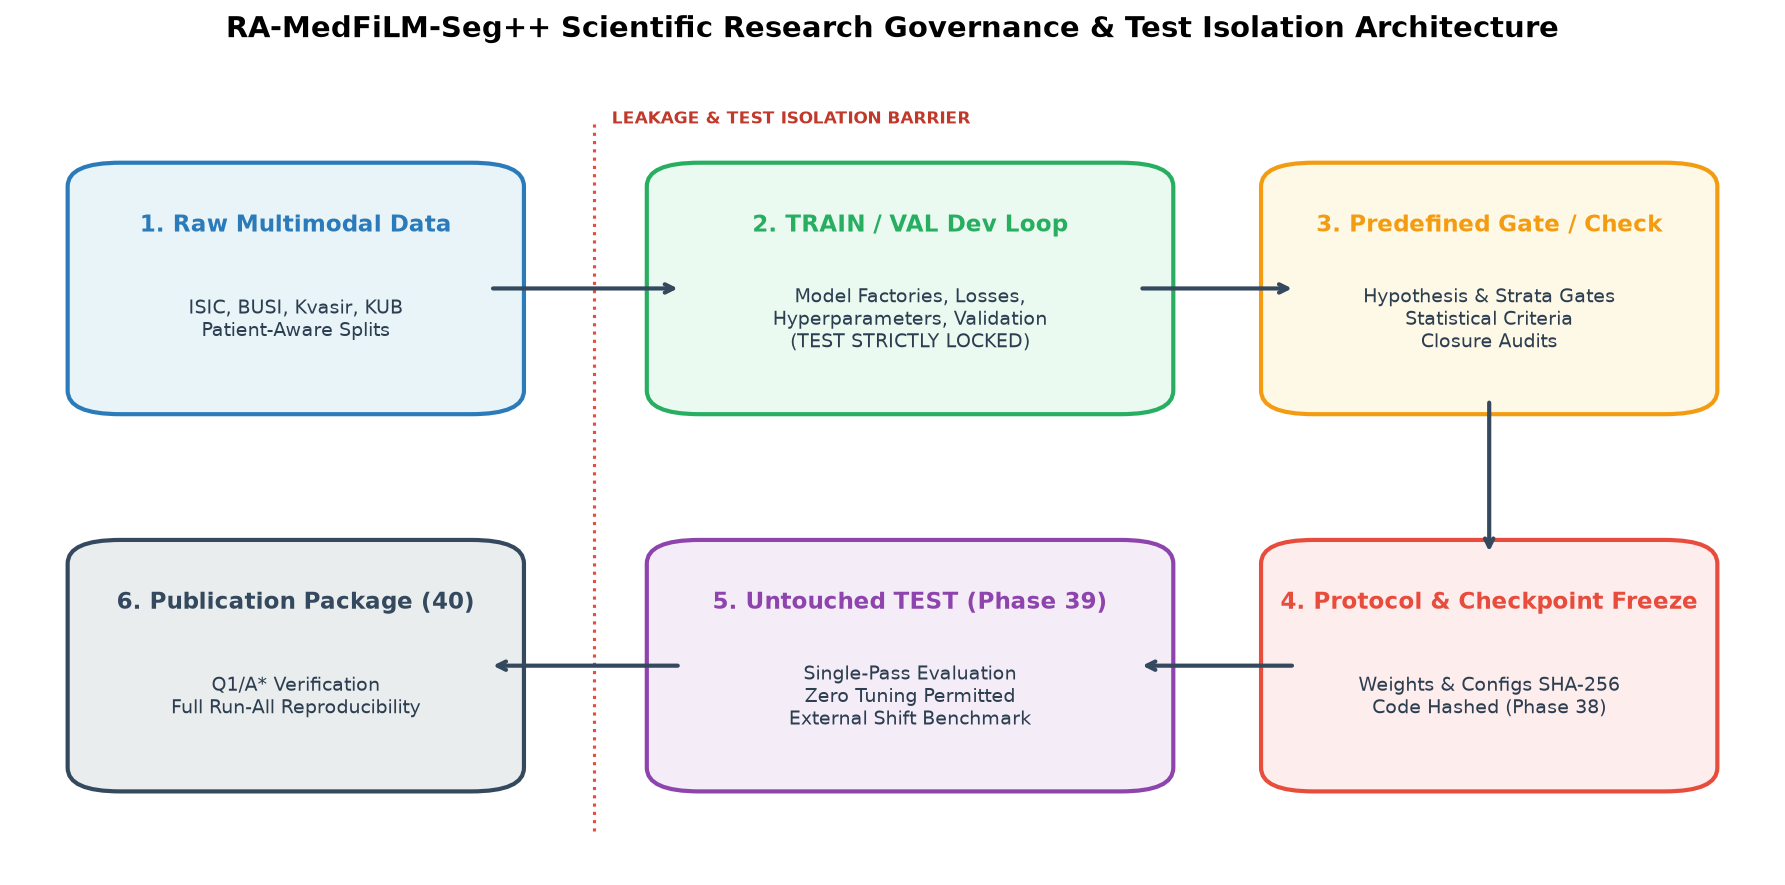

In [5]:
fig_path = ROOT / 'reports/figures/phase00_governance/phase00_governance_flow.png'
if fig_path.exists():
    display(Image(filename=str(fig_path), width=950))
else:
    print("Governance flow diagram not found at:", fig_path)


## Section 11: Current Governance State & Project Audit

Below is the verified state loaded from the authoritative handoff and current state tracking artifacts:


In [6]:
state_file = ROOT / 'reports/audits/antigravity_current_state.json'
with open(state_file, 'r', encoding='utf-8') as f:
    cur_state = json.load(f)

df_status = pd.DataFrame([
    {"Governance Dimension": "Phase 14 Status", "State Value": str(cur_state.get("phase14_status")) + " (" + str(cur_state.get("phase14_classification")) + ")"},
    {"Governance Dimension": "Phase 14 Frozen", "State Value": "YES (b5b329d1... verified)"},
    {"Governance Dimension": "Current Scientific Phase", "State Value": "Phase " + str(cur_state.get("current_phase")) + " (" + str(cur_state.get("current_phase_status")) + ")"},
    {"Governance Dimension": "Phase 15 Training Authorized", "State Value": "NO (Protocol Design & Pre-Training Audit Only)"},
    {"Governance Dimension": "Phase 16 Started", "State Value": "NO (NOT_STARTED)"},
    {"Governance Dimension": "Untouched TEST Set Locked", "State Value": "YES (1,683 cases, 0 reads, NONE metrics)"},
    {"Governance Dimension": "External Dataset Contamination", "State Value": "NONE (external_used = False)"},
    {"Governance Dimension": "Reference Experiment A Modified", "State Value": "NO (experiment_a_modified = False)"},
    {"Governance Dimension": "Next Authorized Action", "State Value": "WAIT_FOR_SUPERVISOR_REVIEW"}
])
display(HTML("<h4>Current Scientific Research Governance Status</h4>"))
display(df_status)


,Governance Dimension,State Value
0,Phase 14 Status,COMPLETE (DIAGNOSTIC_PRACTICAL_SIGNAL_INSUFFIC...
1,Phase 14 Frozen,YES (b5b329d1... verified)
2,Current Scientific Phase,Phase 15 (PROTOCOL_DESIGN)
3,Phase 15 Training Authorized,NO (Protocol Design & Pre-Training Audit Only)
4,Phase 16 Started,NO (NOT_STARTED)
5,Untouched TEST Set Locked,"YES (1,683 cases, 0 reads, NONE metrics)"
6,External Dataset Contamination,NONE (external_used = False)
7,Reference Experiment A Modified,NO (experiment_a_modified = False)
8,Next Authorized Action,WAIT_FOR_SUPERVISOR_REVIEW


## Section 12: Phase 00 Conclusion & Scope Handoff

### What Was Established
1. **Test Isolation:** Certified that the untouched test cohort (1,683 cases) remains cryptographically sealed with zero content reads and zero metrics evaluated.
2. **Experiment & Change Control:** Documented the immutable experiment ID contract, continuity checks for resumption, and supervisor change-control gates.
3. **Artifact Provenance:** Verified the cryptographic immutability of historical canonical notebooks (Phase 14 SHA-256: `b5b329d1...`).
4. **Executable Audit Script:** Deployed `notebooks/phasewise/phase_00_governance/code/phase00_governance_audit.py` for automated reviewer validation.

### What is Frozen
- Research governance protocols, test lock thresholds, and computational environment certifications.

### What Phase 01 Adds
- **Phase 01 (Project Initialization):** Formalizes repository directory structure, source module architecture (`src/data`, `src/models`, `src/metrics`), path resolution contracts, and data loader pipelines.
